# Baseline Reproduction
How closely does the thesis baseline reproduce the one-shot AnomalyDINO-S (448) result across MVTec AD? This notebook verifies all 45 archived run rows, then equally weights the three references within each category and the 15 categories across the benchmark.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
folder = root / "reports/baseline_reproduction"
runs = pd.read_csv(folder / "per_run.csv")
manifest = json.loads((root / "protocols/adino_mvtec_1shot_448_references.json").read_text())
expected = {(cat, int(seed)): ref for cat, refs in manifest["references"].items() for seed, ref in refs.items()}
assert len(runs) == len(expected) == 45 and not runs.duplicated(["category","seed"]).any()
assert set(zip(runs.category, runs.seed)) == set(expected)
for row in runs.itertuples():
    ref = expected[row.category, row.seed]
    assert (row.reference, row.reference_sha256) == (ref["path"], ref["sha256"])
print(f"{runs.category.nunique()} categories × {runs.seed.nunique()} references; {len(runs)} verified run rows")

15 categories × 3 references; 45 verified run rows


## Primary and secondary metrics
Image AUROC, AP, and F1-max assess image scores. Pixel AUROC, F1-max, and AUPRO assess localization. Pixel AUPRO integrates region overlap up to a false-positive rate of 0.30. F1-max uses the best threshold for the evaluated scores.

In [2]:
paper_percent = pd.Series({"image_auroc":96.5, "image_ap":98.1, "image_f1max":96.0,
                           "pixel_auroc":96.3, "pixel_f1max":57.9, "pixel_aupro":91.7})
metrics = paper_percent.index.tolist()
by_category = runs.groupby("category")[metrics].mean()
macro = by_category.mean()
archived = json.loads((folder / "summary.json").read_text())["metrics"]
np.testing.assert_allclose(macro, [archived[m]["macro_mean"] for m in metrics], atol=1e-12, rtol=0)
comparison = pd.DataFrame({"Thesis (%)":100 * macro, "Paper (%)":paper_percent,
                           "Difference (pp)":100 * macro - paper_percent})
display(comparison.round(3))

,Thesis (%),Paper (%),Difference (pp)
image_auroc,96.519,96.5,0.019
image_ap,98.145,98.1,0.045
image_f1max,95.957,96.0,-0.043
pixel_auroc,96.262,96.3,-0.038
pixel_f1max,57.939,57.9,0.039
pixel_aupro,91.720,91.7,0.020


Published comparison: Damm et al., *AnomalyDINO: Boosting Patch-based Few-shot Anomaly Detection with DINOv2*, WACV 2025, Table 2, one shot, AnomalyDINO-S (448). The published means are rounded to one decimal percentage point; differences at that scale cannot establish improvement.

## Variation across categories
Sort by region overlap to see where localization is hardest. The three references share test images, so variation across references measures reference sensitivity.

,image_auroc,image_ap,image_f1max,pixel_auroc,pixel_f1max,pixel_aupro
category,,,,,,
transistor,90.89,87.00,83.18,84.00,39.57,64.36
zipper,98.85,99.71,98.47,92.26,44.78,83.19
cable,91.56,95.61,88.68,93.45,62.81,88.19
tile,99.98,99.99,99.80,95.80,65.12,88.65
screw,89.15,95.98,90.31,97.88,38.33,90.78
metal_nut,99.89,99.97,99.82,95.96,73.32,93.77
wood,98.83,99.65,97.80,94.71,65.31,93.86
toothbrush,99.63,99.86,98.87,99.14,65.25,94.34
grid,99.19,99.75,99.12,99.12,46.03,96.09


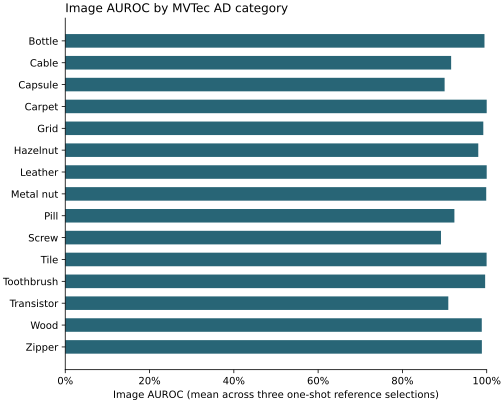

In [3]:
display((100 * by_category.sort_values("pixel_aupro")).round(2))
from IPython.display import SVG
display(SVG(filename=str(folder / "figures/image_auroc.svg")))

The six reproduced macro means agree with the published means at the paper's displayed precision. These clean-condition results supply the paired baselines for [Lighting and Blur Robustness](lighting_and_blur_robustness.ipynb).